In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report,f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
import warnings
warnings.filterwarnings('ignore')

In [47]:
df = pd.read_csv('heart.csv')

In [48]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [49]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [50]:
df.shape

(918, 12)

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [52]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

<Axes: >

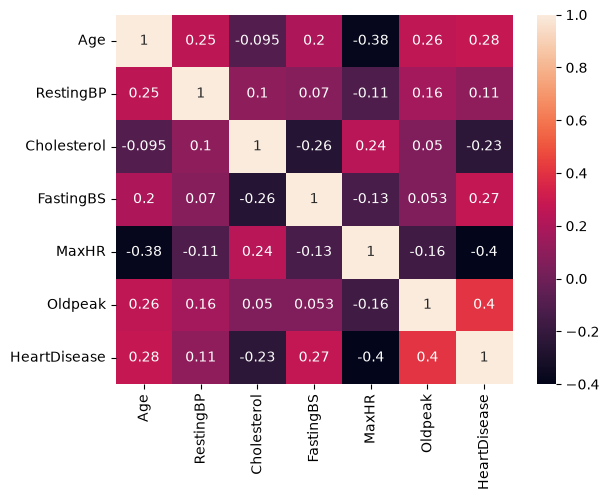

In [53]:
sns.heatmap(df.corr(numeric_only=True),annot= True)

In [54]:
df =pd.get_dummies(df,columns=['ChestPainType','ExerciseAngina','ST_Slope'])

In [55]:
df['Sex']=df['Sex'].map({'F':0,'M':1})

In [56]:
df.drop(['RestingECG'],axis=1,inplace=True)

In [57]:
df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0.0,0,False,True,False,False,True,False,False,False,True
1,49,0,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,1,130,283,0,98,0.0,0,False,True,False,False,True,False,False,False,True
3,48,0,138,214,0,108,1.5,1,True,False,False,False,False,True,False,True,False
4,54,1,150,195,0,122,0.0,0,False,False,True,False,True,False,False,False,True


In [58]:
df =df.astype(int)

In [59]:
x=df.drop('HeartDisease',axis=1)
x_unscaled=x.copy()
y=df['HeartDisease']
scaler = StandardScaler()

In [60]:
x=scaler.fit_transform(x)

In [61]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

In [62]:
models={
    'lg' : LogisticRegression(),
    'dt' : DecisionTreeClassifier(),
    'knn' : KNeighborsClassifier(),
    'rf' : RandomForestClassifier(),
    'svm' : SVC(),
    'nb' : GaussianNB()
}

In [63]:
result = []

In [64]:
for name,model in models.items():
  model.fit(x_train,y_train)
  y_pred = model.predict(x_test)
  acc = accuracy_score(y_test,y_pred)
  f1= f1_score(y_test,y_pred)
  result.append({
      'model': name,
      'accuracy': round(acc,3),
      'f1_score':round(f1,3)
  })



In [65]:
print(pd.DataFrame(result))

  model  accuracy  f1_score
0    lg     0.881     0.897
1    dt     0.762     0.784
2   knn     0.855     0.869
3    rf     0.888     0.903
4   svm     0.894     0.910
5    nb     0.855     0.871


In [66]:
import joblib

In [67]:
joblib.dump(models['svm'],'svm_heart.pkl')
joblib.dump(scaler,'scaler.pkl')
joblib.dump(x_unscaled.columns.tolist(),'columns.pkl')

['columns.pkl']